Epoch 1/80


c:\Users\KYRIACOS PLYSIS\Desktop\Thesis\MyProject3\venv\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6080 - loss: 0.6744 - val_accuracy: 0.7821 - val_loss: 0.5338
Epoch 2/80
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6846 - loss: 0.5789 - val_accuracy: 0.8067 - val_loss: 0.4627
Epoch 3/80
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7614 - loss: 0.4938 - val_accuracy: 0.8223 - val_loss: 0.4001
Epoch 4/80
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8101 - loss: 0.4285 - val_accuracy: 0.8405 - val_loss: 0.3533
Epoch 5/80
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8104 - loss: 0.4205 - val_accuracy: 0.8470 - val_loss: 0.3255
Epoch 6/80
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8151 - loss: 0.3978 - val_accuracy: 0.8508 - val_loss: 0.3012
Epoch 7/80
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8381 - loss: 0.3582 - val_accuracy: 0.8911 - val_loss: 0.2825
Epoch 8/80
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8415 - loss: 0.3488 - val_accuracy: 0.8885 - val_loss: 0.2671
Epo

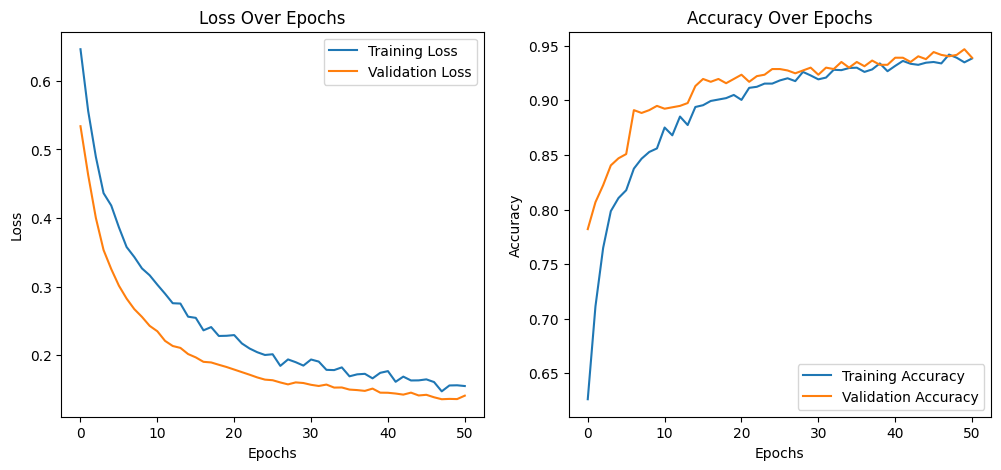


🧪 Final Evaluation on Held-out Test Set:
  Loss: 0.1141
  Accuracy: 95.57%


In [4]:
import matplotlib.pyplot as plt  
from tensorflow.keras.models import Sequential  
from tensorflow.keras.layers import Dense, Dropout  
from tensorflow.keras.optimizers import Adam  
from tensorflow.keras.callbacks import EarlyStopping  
from sklearn.model_selection import train_test_split  
from sklearn.preprocessing import StandardScaler  
import pandas as pd  

# # Load the BPSO filtered dataset for eMBB
# df = pd.read_csv('FL_5GSlices_subsets/eMBB_bpso_global.csv') 

# # Load the BPSO filtered dataset for URLLC
# df = pd.read_csv('FL_5GSlices_subsets/URLLC_bpso_global.csv')

# # Load the BPSO filtered dataset for mMTC
# df = pd.read_csv('FL_5GSlices_subsets/mMTC_bpso_global.csv')

# # Load the BPSO filtered dataset for spli1
# df = pd.read_csv('FL_EqSplit_subsets/split1.csv')

# # Load the BPSO filtered dataset for spli2
# df = pd.read_csv('FL_EqSplit_subsets/spli2.csv')

# Load the BPSO filtered dataset for split3
df = pd.read_csv('FL_EqSplit_subsets/split1.csv')

# Separate features (X) and target (y)
X = df.drop(columns=['Label']) 
y = df['Label'] 


X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features for better training (helps with gradient descent convergence)
scaler = StandardScaler() 
X_train = scaler.fit_transform(X_train)  
X_val = scaler.transform(X_val)  

# Build the Neural Network Model
model = Sequential([
    Dense(16, input_dim=X_train.shape[1], activation='relu'),  
    Dropout(0.3),  
    Dense(8, activation='relu'),  
    Dropout(0.3),  
    Dense(1, activation='sigmoid')  
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), 
    loss='binary_crossentropy',  
    metrics=['accuracy'])  

#Add EarlyStopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss',  
    patience=3, 
    restore_best_weights=True)  

# Train the model
history = model.fit(X_train, y_train, 
    validation_data=(X_val, y_val), 
    epochs=80, 
    batch_size=32,  
    callbacks=[early_stopping]
    ) 

# Function to plot training history (loss and accuracy)
def plot_training_history(history):
    # Plot Loss
    plt.figure(figsize=(12, 5))

    # Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Accuracy Curve
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()

plot_training_history(history)

# Evaluate on the real test set

# # Load the test set for eMBB
# df_test = pd.read_csv("FL_5GSlices_subsets/eMBB_test_set.csv")

# # Load the test set for URLLC
# df_test = pd.read_csv("FL_5GSlices_subsets/URLLC_test_set.csv")

# # Load the test set for mMTC
# df_test = pd.read_csv("FL_5GSlices_subsets/mMTC_test_set.csv")

# Load the test set for split1, split2, split3
df_test = pd.read_csv("FL_5GSlices_subsets/global_test_set.csv")

# Separate features and target
X_test = df_test.drop(columns=["Label"])
y_test = df_test["Label"]

# Scale using the same scaler fitted on training data
X_test = scaler.transform(X_test)

# Evaluate the trained model
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("\n🧪 Final Evaluation on Held-out Test Set:")
print(f"  Loss: {test_loss:.4f}")
print(f"  Accuracy: {test_accuracy * 100:.2f}%")
